In [18]:
import torch
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']  # 解决Windows系统中文显示问题
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题
import os
# 📌📌解决Jupyter报错: "OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized.", 不然plt画不出图一直卡住或者Jupyter崩溃
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

- 神经网络中如果不使用激活函数, 每一层都是上一层输出的线性组合, 那么无论网络有多少层, 都可以被简化为一个线性函数, 无法拟合复杂规律(非线性函数)
- 于是往神经网络中引入激活函数, 一般是非线性的, 对每一层的输出进行非线性变换(扭曲, 截断), 使得神经网络可以拟合复杂规律(非线性函数)

## Sigmoid函数
- Sigmoid函数是一个S型曲线, 将输入映射到(0, 1)之间, 公式为:
$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

- Sigmoid函数的导数为:
$$\sigma'(x) = (\frac{1}{1 + e^{-x}})' = \sigma(x)(1 - \sigma(x))$$

其极值点为 $\sigma(x)=0.5 <=> x=0$, 极大值为 $\sigma'(0)=0.25$

### 饱和问题

当输入值超出`[-6, 6]`时, 输出值接近于0或1并且导数接近于0, 会丢失输入数据的规模信息
<br>
(例如10和10000的输出值都接近1, 但是它们相差1000倍的信息就丢失了)

- 主要用于**二分类问题输出层**, 以及**浅层神经网络隐藏层**(一般5层以内), 层数过多就容易梯度消失

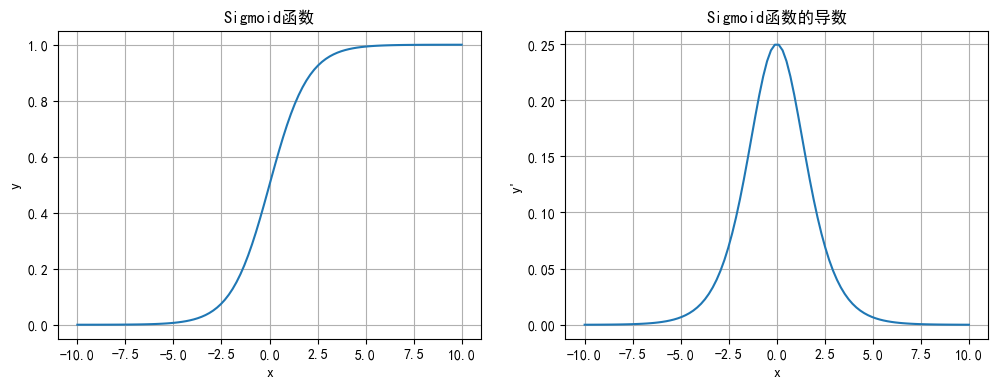

In [22]:
# Sigmoid 函数及其导数的图像
x = torch.linspace(-10, 10, 100)
y = torch.sigmoid(x)
y_prime = y * (1 - y)
_, plots = plt.subplots(1, 2, figsize=(12, 4))
plots[0].plot(x, y)
plots[0].set_title('Sigmoid函数')
plots[0].set_xlabel('x')
plots[0].set_ylabel('y')
plots[0].grid()
plots[1].plot(x, y_prime)
plots[1].set_title('Sigmoid函数的导数')
plots[1].set_xlabel('x')
plots[1].set_ylabel('y\'')
plots[1].grid()

## Tanh函数
- Tanh函数是一个S型曲线, 将输入映射到(-1, 1)之间, 公式为:
$$\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}} = \frac{1 - e^{-2x}}{1 + e^{-2x}}$$
- Tanh函数的导数为:
$$\tanh'(x) = 1 - \tanh^2(x)$$

其极值点为 $\tanh(x)=0 <=> x=0$, 极大值为 $\tanh'(0)=1$

同样存在**饱和问题**: 当输入值超出`[-3, 3]`时, 输出值同样变得平缓, 会导致信息丢失和梯度消失问题

但是Tanh函数的输出值是以0为中心的 (x=0时y也等于0), 相比Sigmoid函数更适合用于神经网络中 <br>
并且Tanh函数的导数在0附近较大, 收敛速度比Sigmoid函数快
- 主要用于**浅层神经网络隐藏层**(一般5层以内), 层数过多就容易梯度消失

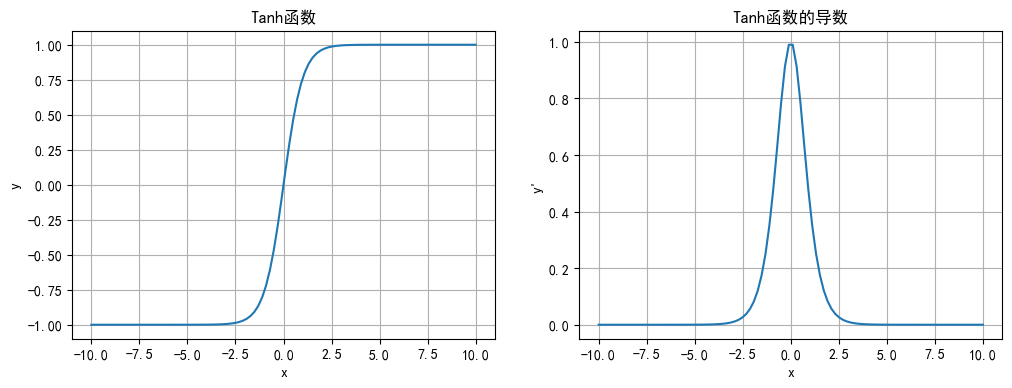

In [23]:
# Tanh 函数及其导数的图像
x = torch.linspace(-10, 10, 100)
y = torch.tanh(x)
y_prime = 1 - torch.pow(y, 2)
_, plots = plt.subplots(1, 2, figsize=(12, 4))
plots[0].plot(x, y)
plots[0].set_title('Tanh函数')
plots[0].set_xlabel('x')
plots[0].set_ylabel('y')
plots[0].grid()
plots[1].plot(x, y_prime)
plots[1].set_title('Tanh函数的导数')
plots[1].set_xlabel('x')
plots[1].set_ylabel('y\'')
plots[1].grid()

## ReLU函数
- ReLU函数是一个分段函数, 将输入映射到[0, +∞)之间, 公式为:
$$ReLU(x) = max(0, x)$$
- ReLU函数的导数为:
$$ReLU'(x) = \begin{cases} 1, & x > 0 \\ 0, & x \leq 0 \end{cases}$$

这样的做法实际上是完全忽略了负值的输入(忽略负样本), 更加重视正信号, 这有利于加快梯度下降.

但是ReLU函数也存在**神经元死亡问题**: 随着训练进行, 当输入值小于0时, 输出值恒为0, 导数也恒为0, 这会导致神经元永远不会被激活, 也无法更新权重, 这部分神经元就永远"死亡"了

但是ReLU函数的计算量小, 收敛速度快, 并且在深层神经网络中表现良好, 因此被广泛使用
- 主要用于**深层神经网络隐藏层**(一般5层以上),

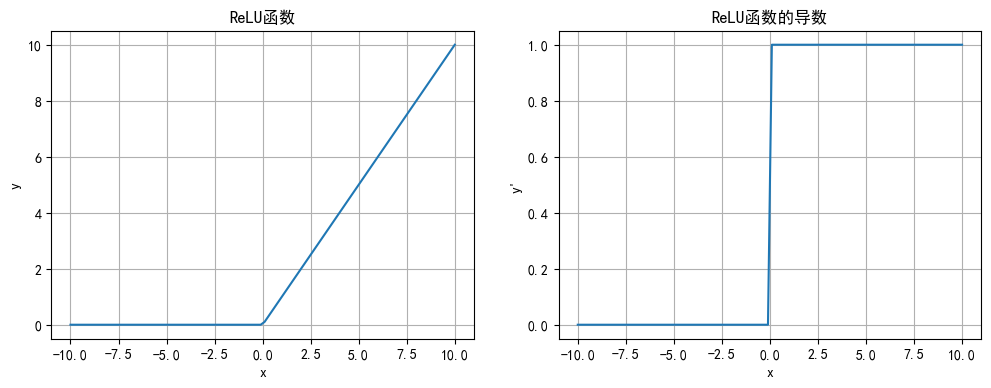

In [24]:
# ReLU 函数及其导数的图像
x = torch.linspace(-10, 10, 100)
y = torch.relu(x)
y_prime = torch.where(x > 0, torch.ones_like(x), torch.zeros_like(x))
_, plots = plt.subplots(1, 2, figsize=(12, 4))
plots[0].plot(x, y)
plots[0].set_title('ReLU函数')
plots[0].set_xlabel('x')
plots[0].set_ylabel('y')
plots[0].grid()
plots[1].plot(x, y_prime)
plots[1].set_title('ReLU函数的导数')
plots[1].set_xlabel('x')
plots[1].set_ylabel('y\'')
plots[1].grid()

## Softmax函数
- Softmax函数是一个多分类激活函数, 将输入映射到(0, 1)之间, 并且所有输出值的和为1, 公式为:
$$Softmax(x_i) = \frac{e^{x_i}}{\sum_{j} e^{x_j}}$$
其中 $x_i$ 是输入向量中的第i个元素 (第i个类别), $j$ 遍历所有元素
- 一般用于**多分类问题输出层**, 将网络的输出值转换为概率分布, 便于进行分类决策 (取概率最大的或者前k个概率最大的类别)

In [36]:
# Softmax 函数用于多分类问题的输出层
torch.manual_seed(123)  # 设置随机种子, 保证每次运行结果相同
x = torch.randn(1, 5)  # 随机生成一个1x5的输入向量, 表示5个类别的得分
y = torch.softmax(x, dim=1)
print(f"输入向量: {x}")
print(f"Softmax输出向量: {y}")
print(f"输出向量的和: {y.sum()}")
print(f"概率最大的类别(索引从0开始): {y.argmax()}")

输入向量: tensor([[-0.1115,  0.1204, -0.3696, -0.2404, -1.1969]])
Softmax输出向量: tensor([[0.2353, 0.2967, 0.1818, 0.2068, 0.0795]])
输出向量的和: 1.0
概率最大的类别: 1
